
## **Project Title: REAL-TIME AIR QUALITY ANALYSIS**



## **Project Goal**
 * Exploratory Data Analysis (EDA) with real-time air-quality data
 * Pollutant & Location-Wise Analysis
 * Statistical Analysis of pollutant measurements
 * Data Visualization using matplotlib and Seaborn
* Insight Generation from air-quality data




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px



* Pandas – Used for data cleaning, data processing, and data analysis.

* NumPy – Used for numerical calculations and working with numerical data.

* Matplotlib – Used to create charts and graphs for data visualization.

* Seaborn – Used to create statistical and informative visualizations.
* Plotly  – Used to create interactive charts and geographical visualizations of air quality data.

In [2]:
df = pd.read_csv("/content/orginal Real time Air Quality Index from various locations Final load.csv")

df = df.copy()


## **Dataset Information**

| Attribute           | Value                                                                                                                                              |
| ------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Source**          | [Data.gov.in - Real Time Air Quality Index from Various Locations](https://www.data.gov.in/resource/real-time-air-quality-index-various-locations) |
| **Original Source** | Central Pollution Control Board (CPCB)                                                                                                             |
| **Records**         | 3,563                                                                                                                                              |
| **Features**        | 11 columns                                                                                                                                         |


##**Dataset Columns**

* Location Details: country, state, city, station
* Date & Time: last_update
* Geographical Coordinates: latitude, longitude
* Pollutant Information: pollutant_id
* Pollutant Measurements: pollutant_min, pollutant_max, pollutant_avg

##**Features List**



* Data loading and cleaning (handling missing values, duplicates, and inconsistent values)
* Data type conversion and preprocessing
* Outlier detection and treatment using the IQR method
* Creating new columns for time-based analysis
* Exploratory data analysis with summary statistics
* Pollutant-wise analysis
* Location-wise air quality analysis
* Statistical analysis of pollutant measurements
* Data visualization using charts and graphs
* Comparison of air quality across different locations and pollutants
* Finding important results from the analysis


In [3]:
df

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg
0,India,Bihar,Begusarai,"Lohiyanagar, Begusarai - BSPCB",24-09-2026 19:00,25.427420,86.138861,NH3,2.0,3.0,3
1,India,Bihar,Begusarai,"Lohiyanagar, Begusarai - BSPCB",24-09-2026 19:00,25.427420,86.138861,CO,41.0,70.0,58
2,India,Bihar,NaN,"Kamalnath Nagar, Bettiah - BSPCB",24-09-2026 19:00,26.803650,84.519540,PM10,19.0,23.0,21
3,India,Bihar,Bhagalpur,"DM Office_Kachari Chowk, Bhagalpur - BSPCB",24-09-2026 19:00,25.251013,86.989001,PM2.5,NaN,NaN,NaN
4,INDIA,Bihar,Bhagalpur,"DM Office_Kachari Chowk, Bhagalpur - BSPCB",24-09-2026 19:00,25.251010,86.989000,CO,28.0,31.0,Fifty
...,...,...,...,...,...,...,...,...,...,...,...
3558,India,West Bengal,Asansol,"Evelyn Lodge, Asansol - WBPCB",24-09-2026 19:00,23.697936,86.944395,OZONE,10.0,14.0,13
3559,India,Telangana,Hyderabad,"Somajiguda, Hyderabad - TSPCB",24-09-2026 19:00,17.417094,78.457437,CO,10.0,10.0,10
3560,India,Uttar Pradesh,Firozabad,"Nagla Bhau, Firozabad - UPPCB",24-09-2026 19:00,27.168897,78.376960,SO2,8.0,124.0,37
3561,India,Uttar Pradesh,Gajraula,"Rajanpur, Gajraula - UPPCB",24-09-2026 19:00,28.829109,78.248796,PM2.5,49.0,168.0,88


In [4]:
df.head()

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg
0,India,Bihar,Begusarai,"Lohiyanagar, Begusarai - BSPCB",24-09-2026 19:00,25.427420,86.138861,NH3,2.0,3.0,3
1,India,Bihar,Begusarai,"Lohiyanagar, Begusarai - BSPCB",24-09-2026 19:00,25.427420,86.138861,CO,41.0,70.0,58
2,India,Bihar,NaN,"Kamalnath Nagar, Bettiah - BSPCB",24-09-2026 19:00,26.803650,84.519540,PM10,19.0,23.0,21
3,India,Bihar,Bhagalpur,"DM Office_Kachari Chowk, Bhagalpur - BSPCB",24-09-2026 19:00,25.251013,86.989001,PM2.5,NaN,NaN,NaN
4,INDIA,Bihar,Bhagalpur,"DM Office_Kachari Chowk, Bhagalpur - BSPCB",24-09-2026 19:00,25.251010,86.989000,CO,28.0,31.0,Fifty


In [5]:
df.tail(10)

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg
3553,India,West Bengal,Kolkata,"Rabindra Sarobar, Kolkata - WBPCB",24-09-2026 19:00,22.511060,88.351420,PM2.5,18.0,20.0,19
3554,India,West Bengal,Kolkata,"Rabindra Sarobar, Kolkata - WBPCB",24-09-2026 19:00,22.511060,88.351420,SO2,6.0,7.0,6
3555,India,West Bengal,Siliguri,"Ward-32 Bapupara, Siliguri - WBPCB",24-09-2026 19:00,26.687923,88.415250,NO2,13.0,20.0,17
3556,India,Arunachal Pradesh,Naharlagun,"Naharlagun, Naharlagun - APSPCB",24-09-2026 19:00,27.103358,93.679645,OZONE,7.0,7.0,7
3557,India,West Bengal,Asansol,"Evelyn Lodge, Asansol - WBPCB",24-09-2026 19:00,23.697936,86.944395,SO2,3.0,12.0,5
3558,India,West Bengal,Asansol,"Evelyn Lodge, Asansol - WBPCB",24-09-2026 19:00,23.697936,86.944395,OZONE,10.0,14.0,13
3559,India,Telangana,Hyderabad,"Somajiguda, Hyderabad - TSPCB",24-09-2026 19:00,17.417094,78.457437,CO,10.0,10.0,10
3560,India,Uttar Pradesh,Firozabad,"Nagla Bhau, Firozabad - UPPCB",24-09-2026 19:00,27.168897,78.376960,SO2,8.0,124.0,37
3561,India,Uttar Pradesh,Gajraula,"Rajanpur, Gajraula - UPPCB",24-09-2026 19:00,28.829109,78.248796,PM2.5,49.0,168.0,88
3562,India,Uttar Pradesh,Gajraula,"Rajanpur, Gajraula - UPPCB",24-09-2026 19:00,28.829109,78.248796,SO2,9.0,13.0,12


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3563 entries, 0 to 3562
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   country        3563 non-null   object 
 1   state          3559 non-null   object 
 2   city           3552 non-null   object 
 3   station        3563 non-null   object 
 4   last_update    3563 non-null   object 
 5   latitude       3563 non-null   float64
 6   longitude      3563 non-null   float64
 7   pollutant_id   3563 non-null   object 
 8   pollutant_min  3225 non-null   float64
 9   pollutant_max  3225 non-null   float64
 10  pollutant_avg  3225 non-null   object 
dtypes: float64(4), object(7)
memory usage: 306.3+ KB


In [7]:
df.shape

(3563, 11)

In [8]:
df.columns

Index(['country', 'state', 'city', 'station', 'last_update', 'latitude',
       'longitude', 'pollutant_id', 'pollutant_min', 'pollutant_max',
       'pollutant_avg'],
      dtype='object')

In [9]:
df.dtypes

,0
country,object
state,object
city,object
station,object
last_update,object
latitude,float64
longitude,float64
pollutant_id,object
pollutant_min,float64
pollutant_max,float64


In [10]:
df.isnull()

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg
0,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False
2,False,False,True,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,True,True,True
4,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
3558,False,False,False,False,False,False,False,False,False,False,False
3559,False,False,False,False,False,False,False,False,False,False,False
3560,False,False,False,False,False,False,False,False,False,False,False
3561,False,False,False,False,False,False,False,False,False,False,False


In [11]:
df.isnull().sum()

,0
country,0
state,4
city,11
station,0
last_update,0
latitude,0
longitude,0
pollutant_id,0
pollutant_min,338
pollutant_max,338


In [12]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
3558,True
3559,True
3560,True
3561,True


##***Data Cleaning***

**Remove Duplicates**
* Duplicate rows were identified using the duplicated() function.
* A total of 7 duplicate rows were found and removed using the drop_duplicates() function.

In [13]:
df.duplicated().sum()

np.int64(7)

In [14]:
df = df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

**Change Data Types**

* The last_update column was initially stored as an object data type and was converted to datetime format using pd.to_datetime function for date time analysis.

* The pollutant_avg column was initially stored as an object data type and was converted to numeric (float) format using pd.to_numeric() funtion for mathematical and statistical calculations.

In [16]:
df = df.copy()

converted_dates = pd.to_datetime(
    df['last_update'],
    dayfirst=True,
    errors='coerce'
)

df = df.assign(last_update=converted_dates)

print(df['last_update'].dtype)

datetime64[ns]


In [17]:
print(df['last_update'].dtype)

datetime64[ns]


In [18]:
print("Fifty count:",
      (df['pollutant_avg'].astype(str).str.strip().str.lower() == 'fifty').sum())

Fifty count: 1


In [19]:
df = df.copy()

converted_avg = pd.to_numeric(
    df['pollutant_avg'],
    errors='coerce'
)

df = df.assign(pollutant_avg=converted_avg)

print(df['pollutant_avg'].dtype)

float64


In [20]:
print("Missing pollutant_avg:", df['pollutant_avg'].isna().sum())

Missing pollutant_avg: 339


In [21]:
df.dtypes

,0
country,object
state,object
city,object
station,object
last_update,datetime64[ns]
latitude,float64
longitude,float64
pollutant_id,object
pollutant_min,float64
pollutant_max,float64


**Handling Missing values**


* Missing values were identified using the isnull().sum() function.

* Missing values in the state and city columns were filled with "Unknown" because the correct location could not be determined reliably.

* Missing values in the pollutant_min, pollutant_max, and pollutant_avg columns were filled using the median of their respective columns.

* After filling the missing values, the dataset was checked again to confirm that no missing values remained.

In [22]:
df.isnull().sum()

,0
country,0
state,4
city,11
station,0
last_update,0
latitude,0
longitude,0
pollutant_id,0
pollutant_min,338
pollutant_max,338


In [23]:
df.loc[:,'state'] = df['state'].fillna("Unknown")


In [24]:
df.loc[:,'city'] = df['city'].fillna("Unknown")


In [25]:
print("Missing state:", df['state'].isna().sum())
print("Missing city:", df['city'].isna().sum())

Missing state: 0
Missing city: 0


In [26]:
df.loc[:,'pollutant_min'] = df['pollutant_min'].fillna(df['pollutant_min'].median())

df.loc[:,'pollutant_max'] = df['pollutant_max'].fillna(df['pollutant_max'].median())

df.loc[:,'pollutant_avg'] = df['pollutant_avg'].fillna(df['pollutant_avg'].median())

In [27]:
print("Missing pollutant_avg:", df['pollutant_avg'].isna().sum())

Missing pollutant_avg: 0


In [28]:
df.isnull().sum()

,0
country,0
state,0
city,0
station,0
last_update,0
latitude,0
longitude,0
pollutant_id,0
pollutant_min,0
pollutant_max,0


**Handle Incorrect and Inconsistent Values**


*  The latitude column was checked for values outside the valid range of -90 to 90 degrees. No incorrect values were found.

* The longitude column was checked for values outside the valid range of -180 to 180 degrees. No incorrect values were found.

* The country column contained both India and INDIA. The inconsistent value INDIA was replaced with India.

* The state column was checked for leading and trailing spaces. Seven values contained extra spaces, which were removed using the strip() function.

* The city column was also cleaned by removing unnecessary leading and trailing spaces.

In [29]:
df[(df['latitude'] < -90) | (df['latitude'] > 90)]

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg


In [30]:
df[(df['longitude'] < -180) | (df['longitude'] > 180)]

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg


In [31]:
df['country'].value_counts()

,count
country,
India,3550
INDIA,6


In [32]:
df.loc[:,'country'] = df['country'].replace('INDIA', 'India')

In [33]:
df['country'].value_counts()

,count
country,
India,3556


In [34]:
df['state'].str.strip().ne(df['state']).sum()

np.int64(7)

In [35]:
df.loc[:,'state'] = df['state'].str.strip()

In [36]:
df['state'].str.strip().ne(df['state']).sum()

np.int64(0)

In [37]:
df['state'].unique()

array(['Bihar', 'Unknown', 'Assam', 'Andhra Pradesh', 'Chandigarh',
       'Chhattisgarh', 'Arunachal Pradesh', 'Delhi', 'Gujarat', 'Haryana',
       'Madhya Pradesh', 'Maharashtra', 'Himachal Pradesh',
       'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh',
       'Meghalaya', 'Mizoram', 'Rajasthan', 'Nagaland', 'Odisha',
       'Punjab', 'Tamil Nadu', 'Telangana', 'Uttar Pradesh', 'Sikkim',
       'Uttarakhand', 'West Bengal', 'madhya Pradesh', 'Puducherry',
       'gujarat', 'Tripura', 'bihar'], dtype=object)

In [38]:
df.loc[:,'state'] = df['state'].replace({
    'madhya Pradesh': 'Madhya Pradesh',
    'gujarat': 'Gujarat',
    'bihar': 'Bihar'
})

In [39]:
df['city'].value_counts()

,count
city,
Delhi,307
Mumbai,154
Hyderabad,91
Bengaluru,56
Ahmedabad,56
...,...
Ajmer,6
Ludhiana,6
Bettiah,6


In [40]:
df.loc[:,'city'] = df['city'].str.strip()

**Handling Outliers Using IQR method**



*   ### Handling Outliers Using IQR Method

* Potential outliers in the **pollutant_min**, **pollutant_max**, and **pollutant_avg** columns were identified using the **Interquartile Range (IQR) method**.
* The IQR was calculated using Q1 and Q3, and the lower and upper limits were determined using **1.5 × IQR**.
* A total of
**227 outliers** were identified in `pollutant_min`,
**335 outliers** in `pollutant_max`,
and **285 outliers** in `pollutant_avg`.
* The identified outliers were **not automatically replaced or removed**, because high pollutant values may represent genuine air-quality measurements.
* The relationship between **pollutant_min, pollutant_avg, and pollutant_max** was also checked to identify internally inconsistent values.
* One record was found where **pollutant_avg was lower than pollutant_min**. Since the correct value could not be reliably determined, the original values were retained.




In [41]:
df[['pollutant_min', 'pollutant_max', 'pollutant_avg']]

,pollutant_min,pollutant_max,pollutant_avg
0,2.0,3.0,3.0
1,41.0,70.0,58.0
2,19.0,23.0,21.0
3,14.0,32.0,23.0
4,28.0,31.0,23.0
...,...,...,...
3551,32.0,48.0,40.0
3552,19.0,46.0,32.0
3553,18.0,20.0,19.0
3554,6.0,7.0,6.0


In [42]:
Q1 = df[['pollutant_min', 'pollutant_max', 'pollutant_avg']].quantile(0.25)
Q3 = df[['pollutant_min', 'pollutant_max', 'pollutant_avg']].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1- 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


In [43]:
outliers = (
    (df[['pollutant_min', 'pollutant_max', 'pollutant_avg']] < lower_limit) |
    (df[['pollutant_min', 'pollutant_max', 'pollutant_avg']] > upper_limit)
)

print("Number of outliers:")
print(outliers.sum())

Number of outliers:
pollutant_min    227
pollutant_max    335
pollutant_avg    285
dtype: int64


In [44]:
print("Inconsistent pollutant rows:",
      ((df['pollutant_min'] > df['pollutant_avg']) |
       (df['pollutant_avg'] > df['pollutant_max'])).sum())

Inconsistent pollutant rows: 1


In [45]:
df[
    (df['pollutant_min'] > df['pollutant_avg']) |
    (df['pollutant_avg'] > df['pollutant_max'])
]

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg
4,India,Bihar,Bhagalpur,"DM Office_Kachari Chowk, Bhagalpur - BSPCB",2026-09-24 19:00:00,25.25101,86.989,CO,28.0,31.0,23.0


**Create New Columns**

New columns such as **year**, **month**, and **hour** were extracted from the 'last_update' datetime column to support time-based analysis of air-quality data.

In [46]:
df.loc[:,'year'] = df['last_update'].dt.year


In [47]:
df.loc[:,'month'] = df['last_update'].dt.month

In [48]:
df.loc[:,'hour'] = df['last_update'].dt.hour

In [49]:
df.columns

Index(['country', 'state', 'city', 'station', 'last_update', 'latitude',
       'longitude', 'pollutant_id', 'pollutant_min', 'pollutant_max',
       'pollutant_avg', 'year', 'month', 'hour'],
      dtype='object')

In [50]:
df.shape

(3556, 14)

In [51]:
df[['last_update', 'year', 'month', 'hour']]

,last_update,year,month,hour
0,2026-09-24 19:00:00,2026,9,19
1,2026-09-24 19:00:00,2026,9,19
2,2026-09-24 19:00:00,2026,9,19
3,2026-09-24 19:00:00,2026,9,19
4,2026-09-24 19:00:00,2026,9,19
...,...,...,...,...
3551,2026-09-24 19:00:00,2026,9,19
3552,2026-09-24 19:00:00,2026,9,19
3553,2026-09-24 19:00:00,2026,9,19
3554,2026-09-24 19:00:00,2026,9,19


**Exploratory Data Analysis (EDA)**

In [52]:
df.dtypes

,0
country,object
state,object
city,object
station,object
last_update,datetime64[ns]
latitude,float64
longitude,float64
pollutant_id,object
pollutant_min,float64
pollutant_max,float64


**Analyze Numerical Data**

* The numerical columns were analyzed using the mean, median, minimum, maximum, and standard deviation to understand their central values, range, and variation.

* The numerical columns analyzed were latitude, longitude, pollutant_min, pollutant
-max, and pollutant_avg.

In [53]:
numerical_columns = [
    'latitude', 'longitude', 'pollutant_min', 'pollutant_max', 'pollutant_avg'
]

print("Mean:")
print(df[numerical_columns].mean())

print("\nMedian:")
print(df[numerical_columns].median())

print("\nMinimum:")
print(df[numerical_columns].min())

print("\nMaximum:")
print(df[numerical_columns].max())

print("\nStandard Deviation:")
print(df[numerical_columns].std())



Mean:
latitude         23.402298
longitude        78.549097
pollutant_min    21.203037
pollutant_max    53.098988
pollutant_avg    33.694882
dtype: float64

Median:
latitude         24.312771
longitude        77.292819
pollutant_min    14.000000
pollutant_max    32.000000
pollutant_avg    23.000000
dtype: float64

Minimum:
latitude          8.514909
longitude        70.776774
pollutant_min     0.000000
pollutant_max     0.000000
pollutant_avg     0.000000
dtype: float64

Maximum:
latitude          34.147096
longitude         94.636574
pollutant_min    199.000000
pollutant_max    500.000000
pollutant_avg    338.000000
dtype: float64

Standard Deviation:
latitude          5.149749
longitude         4.850160
pollutant_min    22.100546
pollutant_max    66.531760
pollutant_avg    35.412029
dtype: float64


**Average pollutant reading by pollutant type**

In [54]:
df.groupby('pollutant_id')['pollutant_avg'].mean().sort_values(ascending=False)

,pollutant_avg
pollutant_id,
PM10,68.350394
PM2.5,58.051181
OZONE,33.988189
CO,32.314961
NO2,21.287402
SO2,13.838583
NH3,8.033465


**Average PM2.5 reading by state**

In [55]:
pm25 = df[df['pollutant_id'] == 'PM2.5'].copy()
pm25 = pm25[pm25['state'] != 'Unknown'].copy()


pm25.groupby('state')['pollutant_avg'].mean().sort_values(ascending=False).head(10)

,pollutant_avg
state,
Delhi,120.159091
Haryana,110.133333
Punjab,78.375000
Gujarat,76.800000
Rajasthan,76.166667
Uttar Pradesh,66.044776
Himachal Pradesh,65.000000
Tamil Nadu,50.166667
Maharashtra,46.860465


**Number of unique monitoring stations by state**

In [56]:
df.groupby('state')['station'].nunique().sort_values(ascending=False).head(10)

,station
state,
Maharashtra,86
Uttar Pradesh,67
Rajasthan,48
Delhi,44
Bihar,31
Haryana,30
Madhya Pradesh,23
Karnataka,23
West Bengal,22


**Number of records by city and pollutant**

In [57]:
df.groupby(['city', 'pollutant_id']).size().sort_values(ascending=False).head(10)

city    pollutant_id
Delhi   NH3             44
        PM2.5           44
        SO2             44
        PM10            44
        OZONE           44
        CO              44
        NO2             43
Mumbai  CO              22
        SO2             22
        PM2.5           22
dtype: int64

**Analyze Categorical data**

*Count Categories*

* The `value_counts()` function was used to count the number of records in each category.

* The `country`, `state`, `city`, `station`, and `pollutant_id` columns were analyzed.

* India was the only country in the dataset.

* Maharashtra had the highest number of records among the states, with 602 records.

* Delhi had the highest number of records among the cities, with 307 records.

* There were 508 monitoring stations in the dataset.

* There were 7 pollutant categories, and each pollutant had 508 records.



In [58]:
categorical_columns = [
    'country',
    'state',
    'city',
    'station',
    'pollutant_id'
]

print("Country:")
print(df['country'].value_counts())

print("\nState:")
print(df['state'].value_counts())

print("\nCity:")
print(df['city'].value_counts())

print("\nStation:")
print(df['station'].value_counts())

print("\nPollutant ID:")
print(df['pollutant_id'].value_counts())

Country:
country
India    3556
Name: count, dtype: int64

State:
state
Maharashtra          602
Uttar Pradesh        468
Rajasthan            336
Delhi                307
Bihar                216
Haryana              210
Karnataka            161
Madhya Pradesh       161
West Bengal          154
Gujarat              140
Odisha               133
Andhra Pradesh       112
Chhattisgarh          91
Telangana             91
Tamil Nadu            84
Assam                 62
Punjab                56
Kerala                35
Uttarakhand           21
Chandigarh            21
Jammu and Kashmir     14
Meghalaya             14
Arunachal Pradesh      7
Himachal Pradesh       7
Nagaland               7
Jharkhand              7
Ladakh                 7
Mizoram                7
Puducherry             7
Sikkim                 7
Tripura                7
Unknown                4
Name: count, dtype: int64

City:
city
Delhi        307
Mumbai       154
Hyderabad     91
Bengaluru     56
Ahmedabad     56
      

**Most common categories**

The most common categories were identified using th mode() function.

* Country: India was the most common category.
* State: Maharashtra was the most common state.
* City: Delhi was the most common city.
* Station: Multiple stations had the same highest frequency of 7 records.
* Pollutant ID: All pollutant categories had the same highest frequency of 508 records.

In [59]:
print("Most Common Categories:")

print("\nCountry:")
print(df['country'].mode())

print("\nState:")
print(df['state'].mode())

print("\nCity:")
print(df['city'].mode())

print("\nStation:")
print(df['station'].mode())

print("\nPollutant ID:")
print(df['pollutant_id'].mode())

Most Common Categories:

Country:
0    India
Name: country, dtype: object

State:
0    Maharashtra
Name: state, dtype: object

City:
0    Delhi
Name: city, dtype: object

Station:
0                       Chhatikara, Vrindavan - UPPCB
1             Indira Nagar, Raebareli - NTPC Unchahar
2      15th Mile-Nongthymmai, Byrnihat -Meghalaya PCB
3                          32Bungalows, Bhilai - CECB
4                                AIIMS, Raipur - CECB
                            ...                      
503                              Worli, Mumbai - MPCB
504                  Yamunapuram, Bulandshahr - UPPCB
505                   Yerramukkapalli, Kadapa - APPCB
506                  Zero Point GICI, Gangtok - SSPCB
507                       Zoo Park, Hyderabad - TSPCB
Name: station, Length: 508, dtype: object

Pollutant ID:
0       CO
1      NH3
2      NO2
3    OZONE
4     PM10
5    PM2.5
6      SO2
Name: pollutant_id, dtype: object


**Distribution Analysis**

The numerical columns were analyzed to understand the distribution of the data using:

* Count - Number of non-missing records.

* Mean - average value.

* Standard Deviation - variation or spread of the data.

* Minimum and Maximum - range of values.

* 25% and 75% - lower and upper quartiles.

* 50% - median or middle value.

In [60]:
print(df[['latitude', 'longitude', 'pollutant_min', 'pollutant_max', 'pollutant_avg']].describe())

          latitude    longitude  pollutant_min  pollutant_max  pollutant_avg
count  3556.000000  3556.000000    3556.000000    3556.000000    3556.000000
mean     23.402298    78.549097      21.203037      53.098988      33.694882
std       5.149749     4.850160      22.100546      66.531760      35.412029
min       8.514909    70.776774       0.000000       0.000000       0.000000
25%      19.225702    75.448351       6.000000      14.000000      10.000000
50%      24.312771    77.292819      14.000000      32.000000      23.000000
75%      28.206917    80.458535      28.000000      61.000000      42.000000
max      34.147096    94.636574     199.000000     500.000000     338.000000


**Percentage Analysis**

* The percentage distribution of the categorical columns was analyzed using `value_counts(normalize=True).

* Percentage analysis was used to understand the distribution of records across country, state, city, station, and pollutant categories.

* **India** accounted for **100%** of records, while **Maharashtra** had the highest state share (**16.93%**) and **Delhi** had the highest city share (**8.63%**).

* The dataset contains **508** stations, with each station contributing a small percentage **(0.2%)** of the records.



In [61]:
print("Country Percentage:")
print((df['country'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

print("\nState Percentage:")
print((df['state'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

print("\nCity Percentage:")
print((df['city'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

print("\nStation Percentage:")
print((df['station'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

print("\nPollutant Percentage:")
print((df['pollutant_id'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

Country Percentage:
country
India    100.0%
Name: proportion, dtype: object

State Percentage:
state
Maharashtra          16.93%
Uttar Pradesh        13.16%
Rajasthan             9.45%
Delhi                 8.63%
Bihar                 6.07%
Haryana               5.91%
Karnataka             4.53%
Madhya Pradesh        4.53%
West Bengal           4.33%
Gujarat               3.94%
Odisha                3.74%
Andhra Pradesh        3.15%
Chhattisgarh          2.56%
Telangana             2.56%
Tamil Nadu            2.36%
Assam                 1.74%
Punjab                1.57%
Kerala                0.98%
Uttarakhand           0.59%
Chandigarh            0.59%
Jammu and Kashmir     0.39%
Meghalaya             0.39%
Arunachal Pradesh      0.2%
Himachal Pradesh       0.2%
Nagaland               0.2%
Jharkhand              0.2%
Ladakh                 0.2%
Mizoram                0.2%
Puducherry             0.2%
Sikkim                 0.2%
Tripura                0.2%
Unknown               0.11%
Nam

**Correlation Analysis**

* **pollutant_min** and **pollutant_avg** showed a strong positive correlation **(0.86)**.

* **pollutant_max** and **pollutant_avg** showed a strong positive correlation (**0.90**).

* **latitude** and **pollutant_avg** showed a weak positive correlation **(0.20)**.

* **longitude** and **pollutant_avg** showed a weak negative correlation **(-0.17)**.

In [62]:
print(df[['latitude', 'longitude', 'pollutant_min', 'pollutant_max', 'pollutant_avg']].corr())

               latitude  longitude  pollutant_min  pollutant_max  \
latitude       1.000000   0.094470       0.132588       0.217054   
longitude      0.094470   1.000000      -0.147271      -0.162086   
pollutant_min  0.132588  -0.147271       1.000000       0.636775   
pollutant_max  0.217054  -0.162086       0.636775       1.000000   
pollutant_avg  0.202008  -0.170903       0.858250       0.899918   

               pollutant_avg  
latitude            0.202008  
longitude          -0.170903  
pollutant_min       0.858250  
pollutant_max       0.899918  
pollutant_avg       1.000000  


**Data Visualization**

## Bar Chart

A bar chart was created using Matplotlib to show the number of records for each pollutant type. It helps compare how frequently each pollutant appears in the dataset.

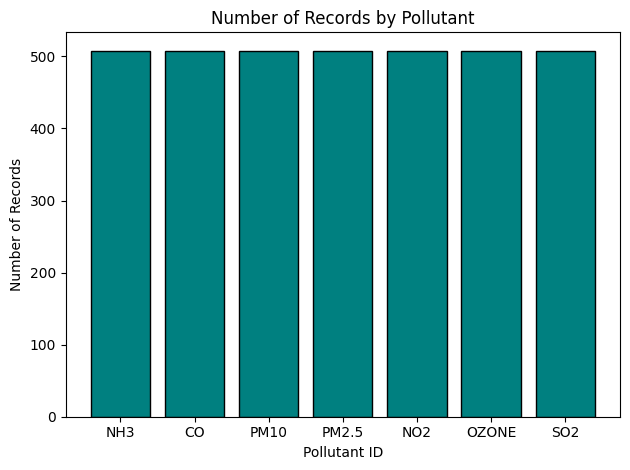

In [63]:
pollutant_counts = df['pollutant_id'].value_counts()

plt.bar(pollutant_counts.index, pollutant_counts.values, color='teal', edgecolor='black')
plt.xlabel("Pollutant ID")
plt.ylabel("Number of Records")
plt.title("Number of Records by Pollutant")

plt.tight_layout()
plt.show()

## Histogram

A histogram was created using Matplotlib to show the distribution of average pollutant readings. It helps identify where the readings are concentrated and how they are spread across different value ranges.

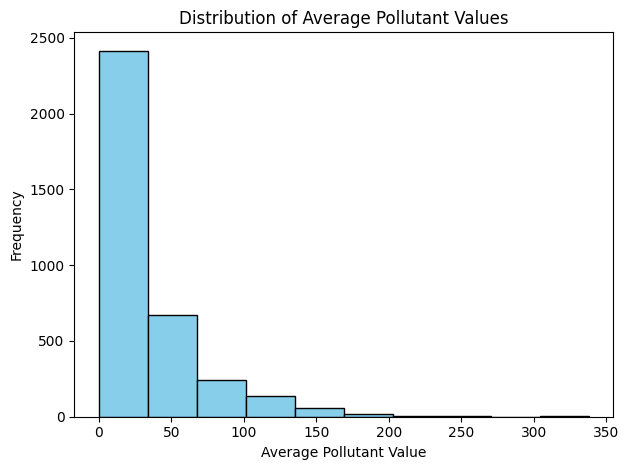

In [64]:
x = (df['pollutant_avg'])

plt.hist(x, bins=10, color='skyblue', edgecolor='black')
plt.xlabel('Average Pollutant Value')
plt.ylabel('Frequency')
plt.title("Distribution of Average Pollutant Values")

plt.tight_layout()
plt.show()

## Box Plot

A box plot was created using Matplotlib to show the median, spread, and potential outliers in average pollutant readings. It helps understand the variation in the recorded values.

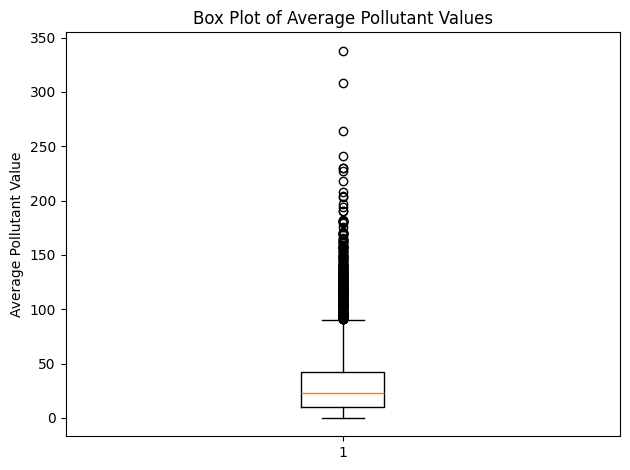

In [65]:
plt.boxplot(df['pollutant_avg'])
plt.ylabel("Average Pollutant Value")
plt.title("Box Plot of Average Pollutant Values")

plt.tight_layout()
plt.show()

##Scatter Plot

A scatter plot was created using Matplotlib to examine the relationship between minimum and average pollutant readings. The plot shows a strong positive relationship, meaning higher minimum readings generally tend to occur alongside higher average readings.

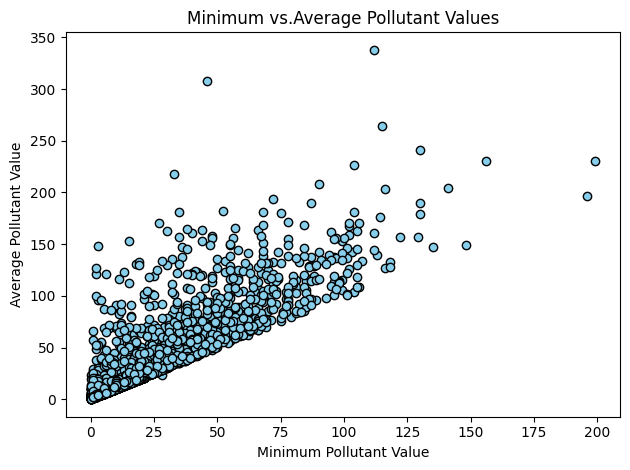

In [66]:
x = df['pollutant_min']
y = df['pollutant_avg']

plt.scatter(x,y, color='skyblue', edgecolors='black')
plt.xlabel("Minimum Pollutant Value")
plt.ylabel("Average Pollutant Value")
plt.title("Minimum vs.Average Pollutant Values")

plt.tight_layout()
plt.show()

## Bar Chart

A bar chart was created using Matplotlib to display the average recorded value for each pollutant type. It summarizes the readings by pollutant.

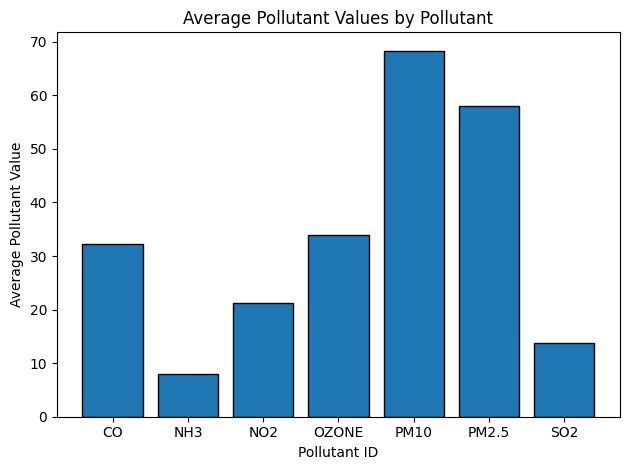

In [67]:
pollutant_avg = df.groupby('pollutant_id')['pollutant_avg'].mean()

plt.bar(pollutant_avg.index, pollutant_avg.values, edgecolor='black')

plt.xlabel("Pollutant ID")
plt.ylabel("Average Pollutant Value")
plt.title("Average Pollutant Values by Pollutant")

plt.tight_layout()
plt.show()

## Seaborn Scatter Plot

A scatter plot was created using Seaborn to show the geographical distribution of monitoring station records. Longitude is shown on the X-axis, latitude on the Y-axis, and colour represents pollutant type.

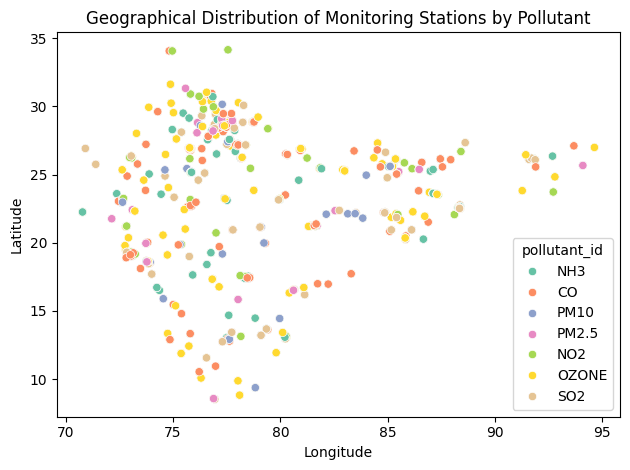

In [68]:
sns.scatterplot(
    x='longitude',
    y='latitude',
    hue='pollutant_id',
    data=df,
    palette='Set2'
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Monitoring Stations by Pollutant")

plt.tight_layout()
plt.show()


## Correlation Heatmap

A correlation heatmap was created using Seaborn to examine the strength and direction of relationships between numerical variables.

- `pollutant_min` and `pollutant_avg` showed a strong positive correlation (0.86).
- `pollutant_max` and `pollutant_avg` showed a strong positive correlation (0.90).
- `latitude` and `pollutant_avg` showed a weak positive correlation (0.20).
- `longitude` and `pollutant_avg` showed a weak negative correlation (-0.17).

Correlation indicates association between variables; it does not prove that one variable causes changes in another.

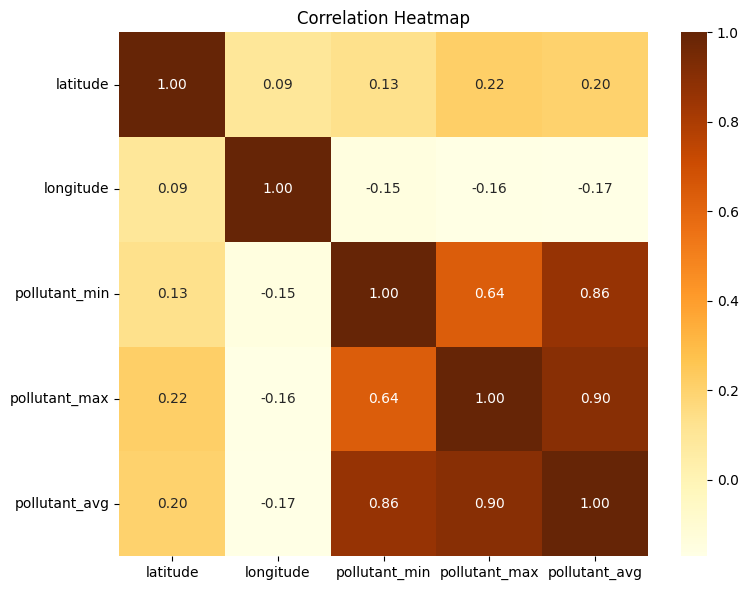

In [69]:
correlation = df[['latitude', 'longitude', 'pollutant_min', 'pollutant_max', 'pollutant_avg']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='YlOrBr', fmt='.2f')

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()


## Interactive Bar Chart – Average Pollutant Values by State

An interactive bar chart was created using Plotly to compare average recorded pollutant values across states. The chart allows users to explore differences between states. Since different pollutant types may have different measurement scales, the results should be interpreted cautiously.

In [70]:
pm25 = df[df['pollutant_id'] == 'PM2.5'].copy()
pm25 = pm25[pm25['state'] != 'Unknown'].copy()

state_avg = pm25.groupby('state')['pollutant_avg'].mean()
state_avg = state_avg.sort_values(ascending=False).head(10)

fig = px.bar(
    state_avg,
    title='Top 10 States by Average PM2.5 Reading',
    labels={'state': 'State', 'value': 'Average PM2.5 Reading'
    },
    color_discrete_sequence=['teal'])

fig.update_layout(
    xaxis_title='State',
    yaxis_title='Average PM2.5 Reading',
)
fig.show()

## Interactive Geographical Scatter Plot – Air Quality by Location

An interactive scatter plot was created using Plotly to explore the geographical distribution of air-quality monitoring records.

- **X-axis:** Longitude
- **Y-axis:** Latitude
- **Colour:** Average pollutant reading
- **Hover details:** Station, city, and state

This visualization helps explore monitoring locations and the variation in recorded pollutant readings.

In [71]:
fig = px.scatter(df,x = 'longitude', y = 'latitude', color = 'pollutant_avg',
    hover_data=['station', 'city', 'state'],
    title = "Air Quality by Location",
    labels={
        'longitude': 'Longitude',
        'latitude': 'Latitude',
        'pollutant_avg': 'Average Pollutant Value'
    },
)

fig.update_layout(xaxis_title='Longitude',yaxis_title='Latitude')
fig.show()